In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [3]:
data=pd.read_csv(r"C:\Users\lenovo\OneDrive\Desktop\machine_learning_mini_project\data\Framingham Dataset.csv")

In [7]:
data=data[data["PERIOD"]==1].copy()

In [9]:
data.isnull().sum()

RANDID         0
SEX            0
TOTCHOL       52
AGE            0
SYSBP          0
DIABP          0
CURSMOKE       0
CIGPDAY       32
BMI           19
DIABETES       0
BPMEDS        61
HEARTRTE       1
GLUCOSE      397
educ         113
PREVCHD        0
PREVAP         0
PREVMI         0
PREVSTRK       0
PREVHYP        0
TIME           0
PERIOD         0
HDLC        4434
LDLC        4434
DEATH          0
ANGINA         0
HOSPMI         0
MI_FCHD        0
ANYCHD         0
STROKE         0
CVD            0
HYPERTEN       0
TIMEAP         0
TIMEMI         0
TIMEMIFC       0
TIMECHD        0
TIMESTRK       0
TIMECVD        0
TIMEDTH        0
TIMEHYP        0
dtype: int64

In [10]:
data["TIME"].value_counts()

TIME
0    4434
Name: count, dtype: int64

In [ ]:
drop_columns_list=["TIME","PERIOD",'TIMEAP', 'TIMEMI', 'TIMEMIFC', 'TIMECHD',
       'TIMESTRK', 'TIMECVD', 'TIMEDTH', 'TIMEHYP','HDLC','LDLC']

In [5]:
features=["SEX","AGE","TOTCHOL","SYSBP","DIABP","CURSMOKE","CIGPDAY","BMI","DIABETES","BPMEDS","HEARTRTE","GLUCOSE","educ","PREVHYP"]

Index(['RANDID', 'SEX', 'TOTCHOL', 'AGE', 'SYSBP', 'DIABP', 'CURSMOKE',
       'CIGPDAY', 'BMI', 'DIABETES', 'BPMEDS', 'HEARTRTE', 'GLUCOSE', 'educ',
       'PREVCHD', 'PREVAP', 'PREVMI', 'PREVSTRK', 'PREVHYP', 'TIME', 'PERIOD',
       'HDLC', 'LDLC', 'DEATH', 'ANGINA', 'HOSPMI', 'MI_FCHD', 'ANYCHD',
       'STROKE', 'CVD', 'HYPERTEN', 'TIMEAP', 'TIMEMI', 'TIMEMIFC', 'TIMECHD',
       'TIMESTRK', 'TIMECVD', 'TIMEDTH', 'TIMEHYP'],
      dtype='str')

In [12]:
data["ANYCHD"].value_counts()

ANYCHD
0    3194
1    1240
Name: count, dtype: int64

In [6]:
X=data[features]
y=data["ANYCHD"]

In [8]:
X.tail()

,SEX,AGE,TOTCHOL,SYSBP,DIABP,CURSMOKE,CIGPDAY,BMI,DIABETES,BPMEDS,HEARTRTE,GLUCOSE,educ,PREVHYP
11622,1,46,173.0,126.0,82.0,0,0.0,19.17,0,0.0,70.0,NaN,3.0,1
11623,1,52,153.0,143.0,89.0,0,0.0,25.74,0,0.0,65.0,72.0,3.0,1
11624,2,39,196.0,133.0,86.0,1,30.0,20.91,0,0.0,85.0,80.0,3.0,0
11625,2,46,240.0,138.0,79.0,1,20.0,26.39,0,0.0,90.0,83.0,3.0,0
11626,2,50,NaN,147.0,96.0,1,10.0,24.19,0,0.0,94.0,NaN,3.0,1


In [17]:
X.isnull().sum()

SEX           0
AGE           0
TOTCHOL      52
SYSBP         0
DIABP         0
CURSMOKE      0
CIGPDAY      32
BMI          19
DIABETES      0
BPMEDS       61
HEARTRTE      1
GLUCOSE     397
educ        113
PREVHYP       0
dtype: int64

In [25]:
from sklearn.experimental import enable_iterative_imputer  
from sklearn.impute import IterativeImputer
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [23]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
mice_imputer=IterativeImputer(max_iter=10,random_state=42)


In [35]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", IterativeImputer(max_iter=10, random_state=42)),
        ("scaler", StandardScaler()),
    ]
)
numeric_transform = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, X_train.columns),
    ],
    remainder="passthrough",
)

In [37]:
X_train_trf=numeric_pipeline.fit_transform(X_train)
X_test_trf=numeric_pipeline.transform(X_test)


In [ ]:
X_train_trf=pd.DataFrame(X_train_trf,columns=numeric_pipeline.get_feature_names_out())


In [40]:
X_test_trf=pd.DataFrame(X_test_trf,columns=numeric_pipeline.get_feature_names_out())

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,roc_curve

In [41]:
def training(model):
    model.fit(X_train_trf,y_train)
    y_pred=model.predict(X_test_trf)
    print(accuracy_score(y_test,y_pred))
    print(f1_score(y_test,y_pred))
    from sklearn.metrics import roc_curve,RocCurveDisplay,auc
    fpr,tpr,threshold = roc_curve(y_test,y_pred)
    roc_auc = auc(fpr,tpr)
    display=RocCurveDisplay(fpr=fpr,tpr=tpr,roc_auc=roc_auc, name='Logistic')
    display.plot()

0.7485907553551296
0.3180428134556575


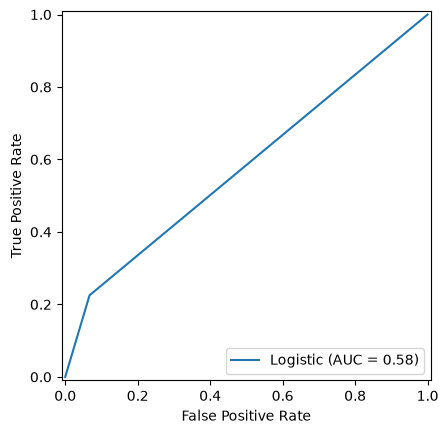

In [42]:
model=LogisticRegression(max_iter=100)
training(model)

In [43]:
from sklearn.model_selection import GridSearchCV

In [47]:
grid_params = {
    "penalty": ["l1", "l2", "elasticnet", None],
    "C": [0.001, 0.01, 0.1, 1, 10, 100],
    "solver": ["lbfgs", "liblinear", "saga", "newton-cg"],
    "max_iter":[100,500],
    "l1_ratio": [0.1, 0.5, 0.9],
}
classifier=GridSearchCV(estimator=LogisticRegression(random_state=42),
                        param_grid=grid_params,
                        scoring='accuracy',
                        n_jobs=1,
                        cv=5,
                        verbose=1,
                        error_score=0
                        
                        )

In [48]:
classifier.fit(X_train_trf,y_train)

Fitting 5 folds for each of 576 candidates, totalling 2880 fits


c:\Users\lenovo\OneDrive\Desktop\machine_learning_mini_project\ml_project_venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\lenovo\OneDrive\Desktop\machine_learning_mini_project\ml_project_venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=n

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.001, 0.01, ...], 'l1_ratio': [0.1, 0.5, ...], 'max_iter': [100, 500], 'penalty': ['l1', 'l2', ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",0
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also

In [49]:
best_model=classifier.best_estimator_
print(best_model)
y_pred=best_model.predict(X_test_trf)
print("Test:",accuracy_score(y_pred,y_test))

LogisticRegression(C=1, l1_ratio=0.1, penalty='l2', random_state=42)
Test: 0.7485907553551296


In [50]:
from sklearn.ensemble import RandomForestClassifier
random_model=RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42
    )

0.7125140924464487
0.46540880503144655


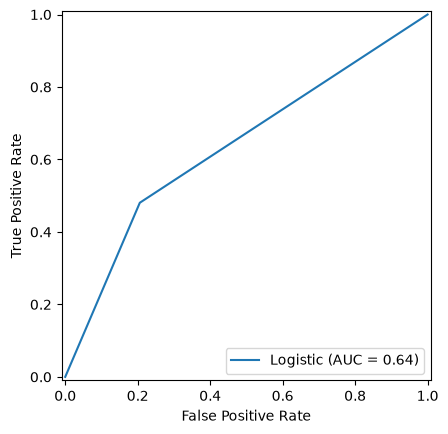

In [51]:
training(random_model)

0.649379932356257
0.3913894324853229


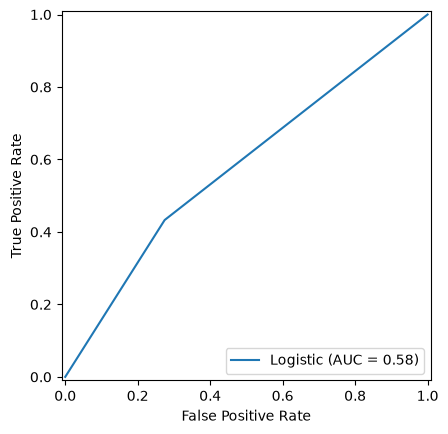

In [52]:
from sklearn.tree import DecisionTreeClassifier
Tree_model=DecisionTreeClassifier()
training(Tree_model)

In [53]:
pipeline = Pipeline([
    ("imputer", IterativeImputer(random_state=42)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(C=1, l1_ratio=0.1, penalty='l2', random_state=42))
])

In [54]:
pipeline.fit(X_train,y_train)

c:\Users\lenovo\OneDrive\Desktop\machine_learning_mini_project\ml_project_venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\lenovo\OneDrive\Desktop\machine_learning_mini_project\ml_project_venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1399: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
c:\Users\lenovo\OneDrive\Desktop\machine_learning_mini_project\ml_project_venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l2 with l1_ratio=0.1. penalty is deprecated. Please

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['SEX','AGE','TOTCHOL',...,'GLUCOSE','educ','PREVHYP']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"random_state random_state: int, RandomState instance or None, default=NoneThe seed of the pseudo random number generator to use. Randomizesselection of estimator features if `n_nearest_features` is not `None`,the `imputation_order` if `random`, and the sampling from posterior if`sample_posterior=True`. Use an integer for determinism.See :term:`the Glossary <random_state>`.",42
,"estimator estimator: estimator object, default=BayesianRidge()The estimator to use at each step of the round-robin imputation.If `sample_posterior=True`, the estimator must support`return_std` in its `predict` method.",None
,"missing_values missing_values: int or np.nan, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`should be set to `np.nan`, since `pd.NA` will be converted to `np.nan`.",nan


In [ ]:
pred=pipeline.predict(X_test)
accuracy_score(y_test,pred)

0.7485907553551296

In [56]:
import os
import joblib

# models folder create karo, agar pehle se nahi hai
os.makedirs("models", exist_ok=True)

# Puri pipeline save karo
joblib.dump(pipeline, "models/heart_model.pkl")

print("Model saved successfully!")

Model saved successfully!
